In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# import warnings
# warnings.filterwarnings('ignore')

In [180]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving cars.csv to cars (8).csv


In [181]:
df.head()

,First_Name,Last_Name,Country,Car_Brand,Car_Model,Car_Color,Year_of_Manufacture,Credit Card Type
0,Yetty,Arghent,Indonesia,Ford,Club Wagon,Teal,1993,mastercard
1,Crystal,Bosworth,China,Cadillac,Escalade ESV,Fuscia,2007,mastercard
2,Monro,Houdhury,Indonesia,Mazda,Miata MX-5,Orange,2009,maestro
3,Bowie,Clair,China,Audi,A4,Orange,2005,instapayment
4,Myrvyn,McAllister,Czech Republic,Nissan,Maxima,Pink,1994,maestro


In [182]:
df.tail()

,First_Name,Last_Name,Country,Car_Brand,Car_Model,Car_Color,Year_of_Manufacture,Credit Card Type
29995,Valida,Smoote,Afghanistan,Nissan,Altima,Yellow,2010,jcb
29996,Anthea,Deport,Indonesia,Kia,Rio,Red,2008,china-unionpay
29997,Albertine,Danelut,Japan,Toyota,Tacoma Xtra,Pink,2004,americanexpress
29998,Alayne,Golda,Kyrgyzstan,Audi,riolet,Turquoise,1996,americanexpress
29999,Ibrahim,Dobrovsky,Indonesia,Lotus,Esprit,Yellow,1991,mastercard


In [183]:
df.duplicated().sum()

np.int64(0)

In [184]:
df.isnull().sum()

,0
First_Name,0
Last_Name,0
Country,0
Car_Brand,0
Car_Model,0
Car_Color,0
Year_of_Manufacture,0
Credit Card Type,0


In [185]:
df.nunique()

,0
First_Name,8173
Last_Name,22192
Country,230
Car_Brand,78
Car_Model,1006
Car_Color,19
Year_of_Manufacture,65
Credit Card Type,16


In [186]:
df = df.fillna(df.mode().iloc[0])

In [187]:
df.head()

,First_Name,Last_Name,Country,Car_Brand,Car_Model,Car_Color,Year_of_Manufacture,Credit Card Type
0,Yetty,Arghent,Indonesia,Ford,Club Wagon,Teal,1993,mastercard
1,Crystal,Bosworth,China,Cadillac,Escalade ESV,Fuscia,2007,mastercard
2,Monro,Houdhury,Indonesia,Mazda,Miata MX-5,Orange,2009,maestro
3,Bowie,Clair,China,Audi,A4,Orange,2005,instapayment
4,Myrvyn,McAllister,Czech Republic,Nissan,Maxima,Pink,1994,maestro


In [188]:
num =  df.select_dtypes(include ='number').columns
df[num] = df[num].fillna(df[num].median())

In [189]:
df.isnull().sum()

,0
First_Name,0
Last_Name,0
Country,0
Car_Brand,0
Car_Model,0
Car_Color,0
Year_of_Manufacture,0
Credit Card Type,0


In [190]:
df.select_dtypes(include = ['int64','float64']).columns

Index(['Year_of_Manufacture'], dtype='object')

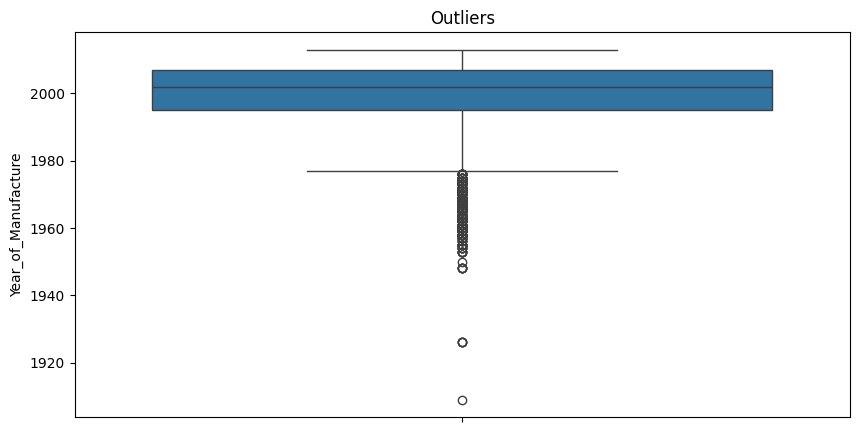

In [191]:
#outlier check
plt.figure(figsize=(10,5))
sns.boxplot(df['Year_of_Manufacture'])
plt.title('Outliers')
plt.show()

In [192]:
Q1 = df['Year_of_Manufacture'].quantile(0.25)
Q3 = df['Year_of_Manufacture'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [193]:
df['Year_of_Manufacture'] = df['Year_of_Manufacture'].clip(lower_bound, upper_bound)

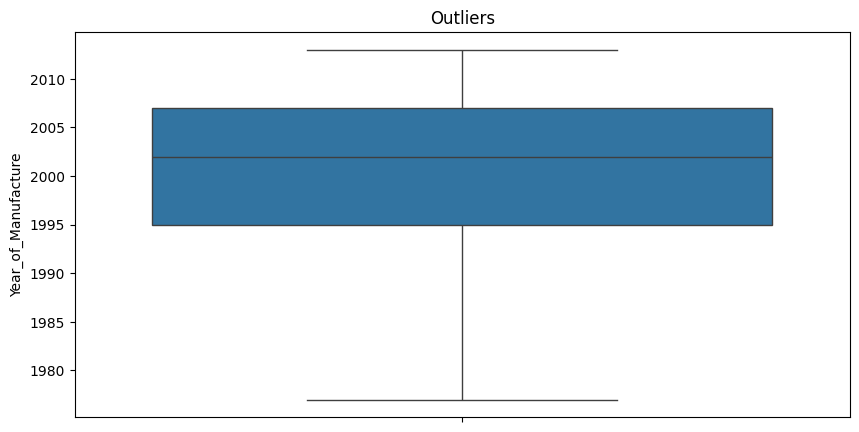

In [194]:
plt.figure(figsize=(10,5))
sns.boxplot(df['Year_of_Manufacture'])
plt.title('Outliers')
plt.show()

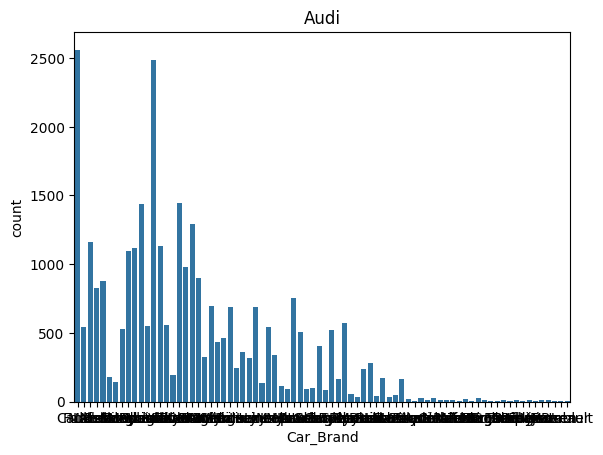

In [195]:
sns.countplot(x = df['Car_Brand'])
plt.title("Audi")
plt.show()

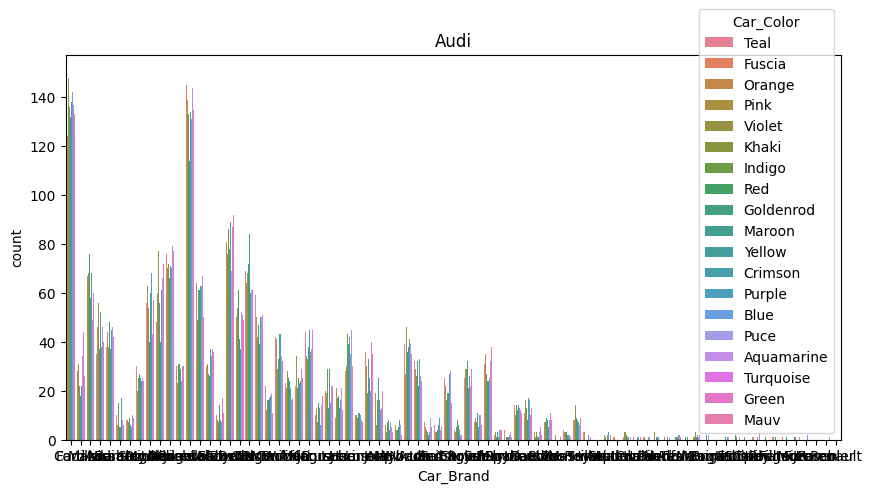

In [196]:
# Bivariate analysis
plt.figure(figsize= (10,5))
sns.countplot(x = df['Car_Brand'], hue = df['Car_Color'])
plt.title("Audi")
plt.show()




In [197]:
sns.catplot(x = 'Car_Brand',hue = 'Car_Color', col = 'Year_of_Manufacture', data = df, kind = 'count')

plt.show()

In [198]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   First_Name           30000 non-null  object
 1   Last_Name            30000 non-null  object
 2   Country              30000 non-null  object
 3   Car_Brand            30000 non-null  object
 4   Car_Model            30000 non-null  object
 5   Car_Color            30000 non-null  object
 6   Year_of_Manufacture  30000 non-null  int64 
 7   Credit Card Type     30000 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.8+ MB


In [199]:
df1= df.select_dtypes(include = 'object').columns
df1

Index(['First_Name', 'Last_Name', 'Country', 'Car_Brand', 'Car_Model',
       'Car_Color', 'Credit Card Type'],
      dtype='object')

In [200]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df1:
  df[col] = le.fit_transform(df[col])


In [201]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   First_Name           30000 non-null  int64
 1   Last_Name            30000 non-null  int64
 2   Country              30000 non-null  int64
 3   Car_Brand            30000 non-null  int64
 4   Car_Model            30000 non-null  int64
 5   Car_Color            30000 non-null  int64
 6   Year_of_Manufacture  30000 non-null  int64
 7   Credit Card Type     30000 non-null  int64
dtypes: int64(8)
memory usage: 1.8 MB


<Axes: xlabel='Car_Brand', ylabel='Density'>

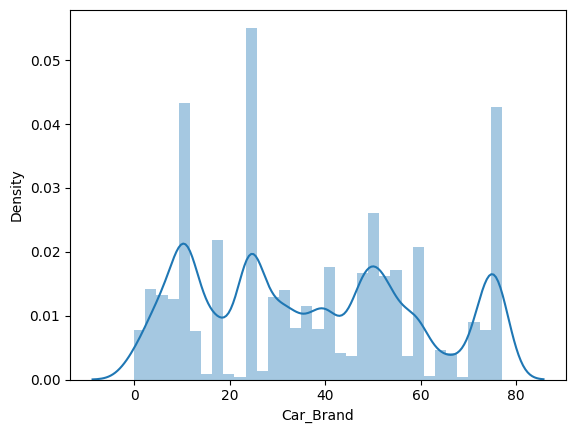

In [202]:
sns.distplot(df['Car_Brand'])

<Axes: xlabel='Car_Brand', ylabel='Car_Model'>

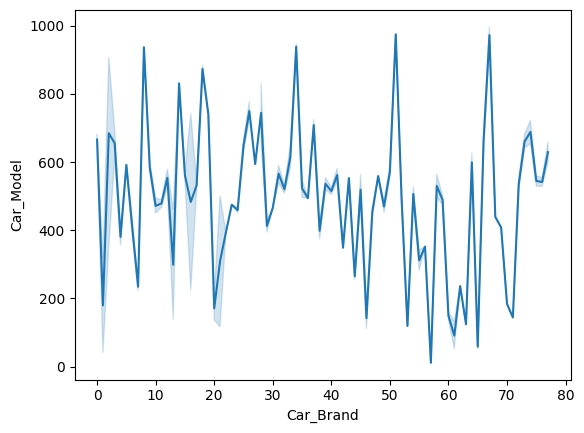

In [203]:
sns.lineplot(x = 'Car_Brand', y = 'Car_Model', data = df)

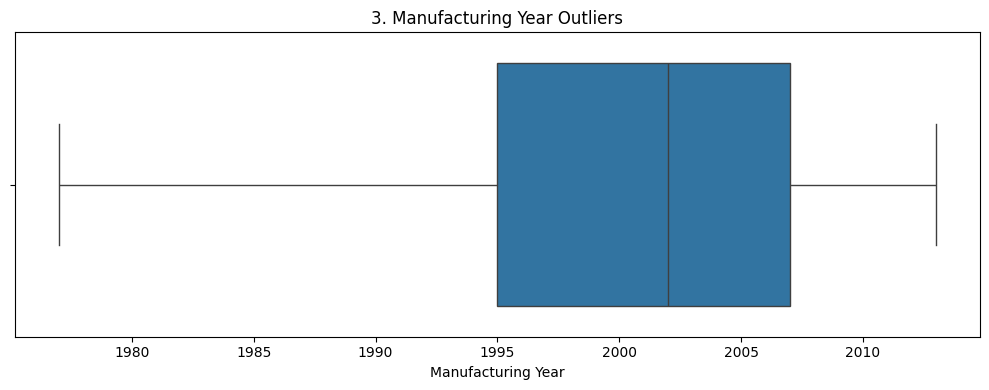

In [204]:
#Box Plot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Year_of_Manufacture"])
plt.title("3. Manufacturing Year Outliers")
plt.xlabel("Manufacturing Year")
plt.tight_layout()
plt.show()

# SHORT NOTE
#Box plot	Highlights unusual manufacturing years


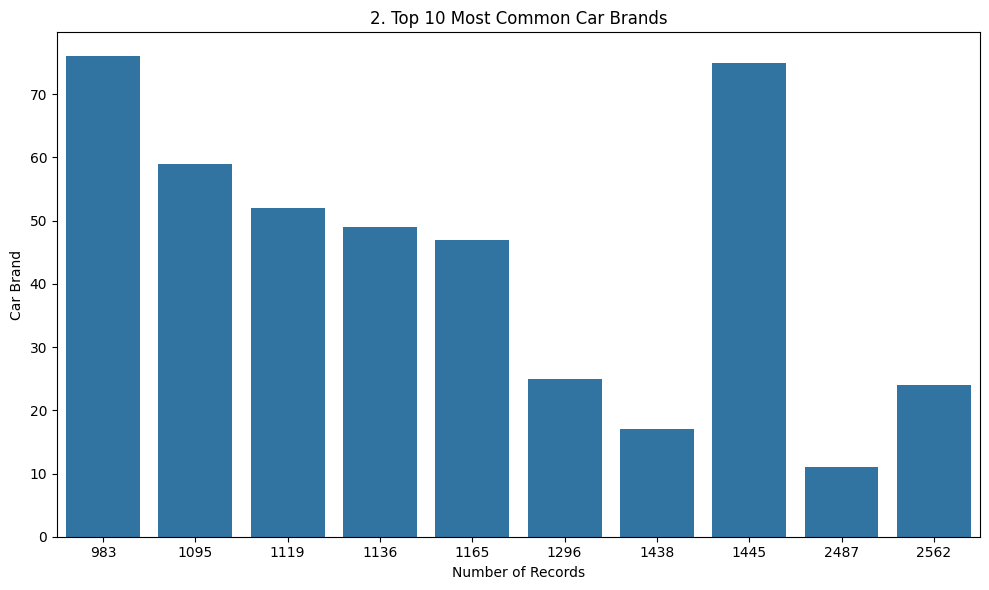

In [205]:
#Bar Chart
top_brands = df["Car_Brand"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("2. Top 10 Most Common Car Brands")
plt.xlabel("Number of Records")
plt.ylabel("Car Brand")
plt.tight_layout()
plt.show()

# SHORT NOTE
#Bar chart	Identifies the most common car brands

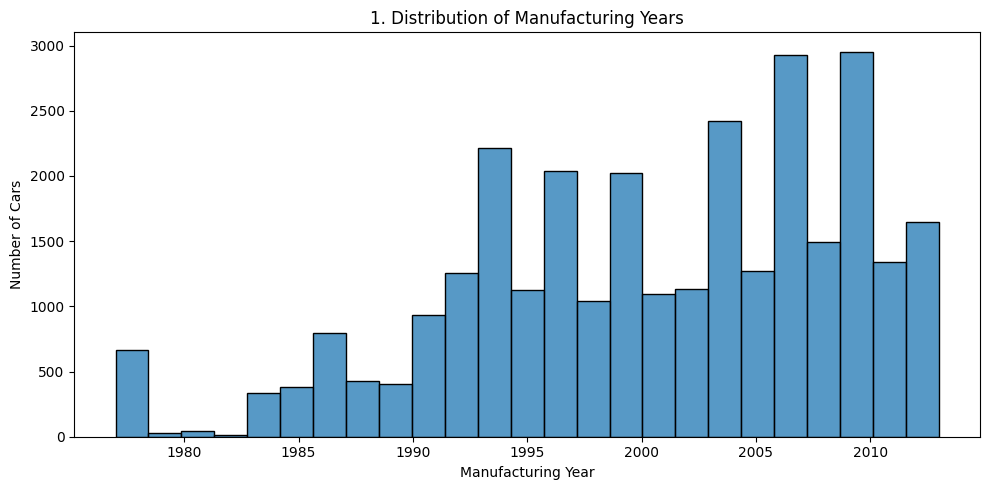

In [206]:
#histogram
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Year_of_Manufacture", bins=25)
plt.title("1. Distribution of Manufacturing Years")
plt.xlabel("Manufacturing Year")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

# SHORT NOTE
#Histogram	Shows the distribution of manufacturing years

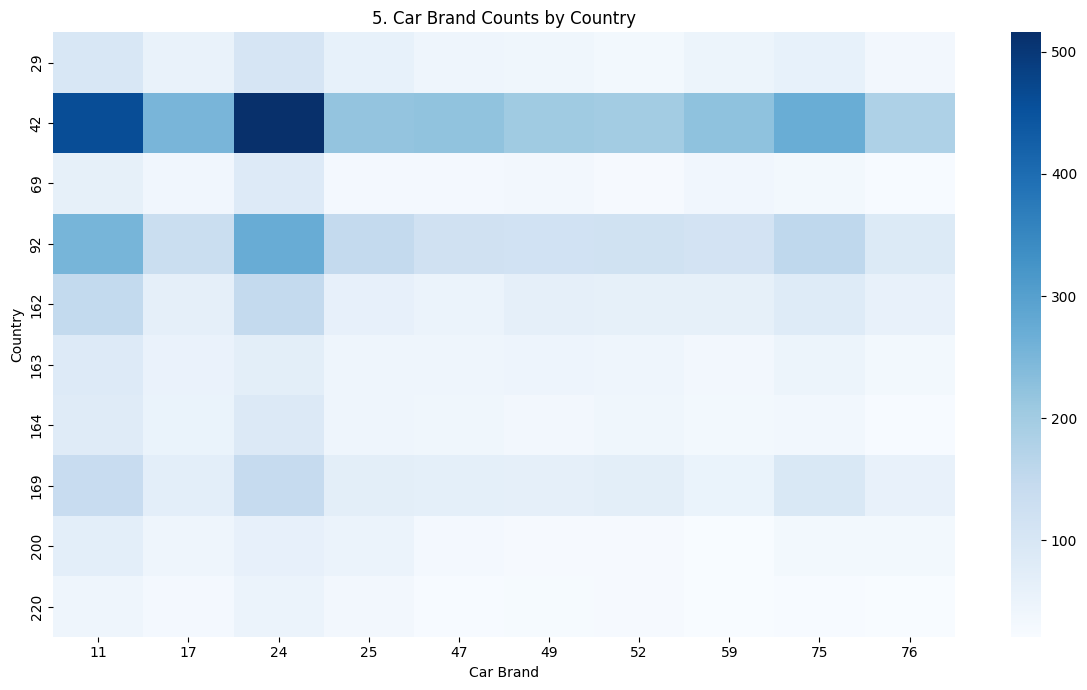

In [207]:
#HEATMAP
top_countries = df["Country"].value_counts().head(10).index
top_brands = df["Car_Brand"].value_counts().head(10).index

subset = df[
    df["Country"].isin(top_countries)
        & df["Car_Brand"].isin(top_brands)
        ]
heatmap_data = pd.crosstab(
subset["Country"],
subset["Car_Brand"]
)
plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_data, annot=False, cmap="Blues")
plt.title("5. Car Brand Counts by Country")
plt.xlabel("Car Brand")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# SHORT NOTE
#Heatmap	Compares brand counts across the most represented countries

**ANALYSIS:**

1. Dataset quality is good

The dataset has 30,000 rows and 8 columns, with zero missing values and zero exact duplicate rows. Four country values contain extra whitespace, which should be cleaned before category analysis.

2. Ford is the most common car brand

Ford appears in 2,562 records (8.54%), followed by Chevrolet with 2,487 records (8.29%). These are the two most frequently recorded brands.

3. Manufacturing years are centered around 2000–2002

The mean manufacturing year is approximately 2000, and the median is 2002. The middle 50% of records fall between 1995 and 2007.

4. China has the most records

China accounts for 5,465 records (18.22%), followed by Indonesia with 3,163 (10.54%). These figures describe the dataset, not necessarily actual vehicle ownership in either country.

5. The dataset contains many distinct models

There are 1,006 distinct car models. Corvette is the most frequent model, appearing 209 times (about 0.70% of all records), indicating that no single model dominates the dataset.